# Otimização de CNN1D Quantizada em Ciclo Fechado (QKeras $\to$ SP/VU13P $\to$ Lagrange/KKT)
## Alocação Primal-Dual de Bits na FPGA Xilinx Virtex UltraScale+ VU13P para o ATLAS L0 Ringer (`v2` = 25 Anéis)

Este notebook implementa de forma enxuta e direta o **ciclo fechado de otimização em 3 estágios** para síntese da CNN1D compacta em hardware FPGA:

```text
  ┌─────────────────────────────────────────────────────────────────────────┐
  │ 1. REDE NEURAL QUANTIZADA (QKeras)                                      │
  │    Configura larguras de bits e arquitetura (w_l, a_l, n_l) + Warm-Start│
  └───────────────────────────────────┬─────────────────────────────────────┘
                                      │
                                      ▼
  ┌─────────────────────────────────────────────────────────────────────────┐
  │ 2. AVALIAÇÃO DE DESEMPENHO E CUSTO                                      │
  │    Calcula a Perda pelo Índice-SP (1 - SP) e estima recursos na VU13P   │
  └───────────────────────────────────┬─────────────────────────────────────┘
                                      │
                                      ▼
  ┌─────────────────────────────────────────────────────────────────────────┐
  │ 3. NÚCLEO DE OTIMIZAÇÃO LAGRANGE / KKT                                  │
  │    Compara uso com limites B_j (LUTs, DSPs, FFs, BRAM), atualiza os     │
  │    Preços de Sombra (μ_j) e recalcula (w_l*, a_l*) até convergência KKT │
  └─────────────────────────────────────────────────────────────────────────┘
```

Todos os artefatos são exportados automaticamente no padrão hierárquico **Jubiaba**:
`<export_dir>/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/` (`saved_models/`, `plots/`, `history/`, `metadata/`, `evaluation/`).


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
import qkeras
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_curve, auc

# Adicionar raiz do repositório ao PYTHONPATH
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.metrics import (
    ESTRUTURA_BASE,
    CONFIG_VERSOES,
    slice_rings_by_version,
    norm1,
    compute_sp,
    compute_sp_with_threshold,
    SPCallback,
)
from src.hardware import (
    VU13P_CHIP_LIMITS,
    VU13P_LIMITS,
    get_vu13p_budget,
    estimate_hardware_resources,
    compute_model_hardware_costs,
)
from src.kkt_allocator import (
    compute_hutchinson_hessian_trace,
    compute_layer_c_coefficients,
    solve_kkt_bit_allocation,
    LagrangeKKTQuantizerOptimizer,
    check_kkt_stopping_criteria,
)
from src.models import (
    build_compact_cnn1d_fp32,
    build_compact_qcnn1d,
    transfer_weights_to_qmodel,
)
from src.exporter import ArtifactExporter
from src.visualization import (
    plot_rings_profile,
    plot_learning_curves,
    plot_best_model_roc,
    plot_cv_roc_envelope,
    plot_output_score_histogram,
    plot_confusion_matrix_knee,
    plot_cv_statistics_boxplots,
    plot_fa_per_fold_workpoints,
    plot_roc_duel_fp32_vs_kkt,
    plot_vu13p_resource_utilization,
    plot_primal_dual_kkt_evolution,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("QKeras Version:", qkeras.__version__)
print("Repository Root:", repo_root)


2026-11-09 22:23:53.498608: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-09 22:23:53.498868: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-09 22:23:53.531377: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-09 22:23:54.494662: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-09 22:23:54.494888: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.20.0
QKeras Version: 0.9.0
Repository Root: /home/iaraujo/Documentos/Github/cnn-optimization


## 1. Ingestão de Dados Ringer (`v2` = 25 Anéis) e Limites de Recursos na FPGA VU13P

Configuramos a região cinemática $(\text{iet}=5, \text{ieta}=0)$, aplicamos o fatiamento físico da topologia `v2` (25 anéis internos do calorímetro) com normalização $L_1$, e definimos os limites de recursos $B_j$ na FPGA **AMD/Xilinx Virtex UltraScale+ VU13P (Tabela 15)**.


,Recurso FPGA (VU13P),Capacidade Total Chip (Tabela 15),Orçamento da Instância (B_j)
0,DSP,"12,288",0
1,LUT,"1,728,000","2,500"
2,FF,"3,456,000","10,000"
3,BRAM_bits,"99,090,432","5,500"


Total de eventos balanceados: 77,126 (38,563 Elétrons / 38,563 Jatos)
Estrutura das camadas em v2 (25 anéis): {'PS': 2, 'EM1': 16, 'EM2': 2, 'EM3': 2, 'HAD1': 1, 'HAD2': 1, 'HAD3': 1}


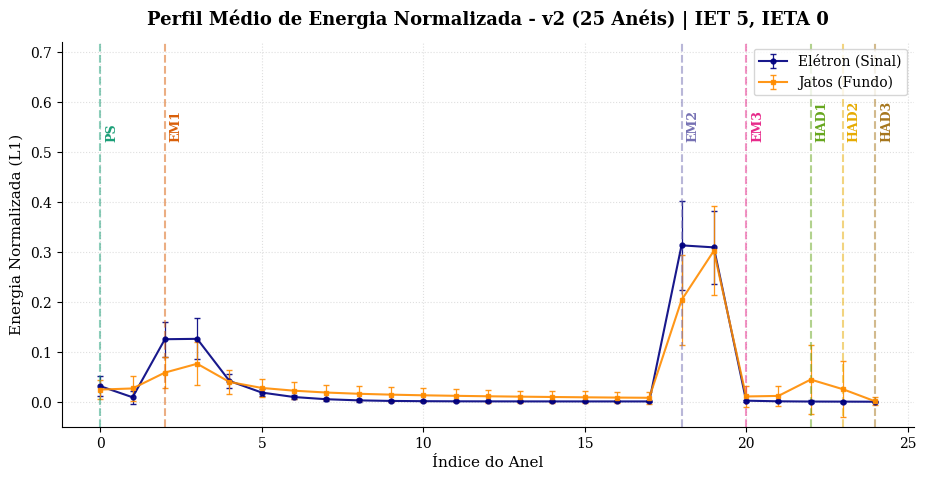

Conjunto de Desenvolvimento (CV): (61700, 25) | Conjunto Holdout Isolado: (15426, 25)


In [2]:
# ==============================================================================
# PARÂMETROS GLOBAIS DO EXPERIMENTO
# ==============================================================================
EXPORT_DIR = os.path.join(repo_root, "results")
DATASET_PREFIX = "mc21_13p6TeV.Zee.JF17.2sigma.5M"
MODEL_NAME = "QCNN1D_KKT"
IET = 5
IETA = 0
VERSION = 2        # 0 (100 anéis), 1 (50 anéis), ou 2 (25 anéis)
N_SPLITS = 5       # Folds para validação cruzada
EPOCHS_CV = 18     # Épocas por fold com Warm-Start e ReduceLROnPlateau

cfg_versao = CONFIG_VERSOES[VERSION]
input_dim = cfg_versao["input_dim"]
kernel_size = cfg_versao["kernel"]
num_filters = cfg_versao["filters"]
dense_units = cfg_versao["dense_units"]

# Orçamento estrito para a instância do classificador L0 Ringer na FPGA VU13P
VU13P_INSTANCE_BUDGET = get_vu13p_budget({
    "DSP": 0.0,          # Zero DSPs (obriga síntese sub-byte <= 8b em CLB LUTs)
    "LUT": 2500.0,       # Teto de 2.500 LUTs (8-bit uniforme requer 4.892 LUTs -> exige compressão KKT)
    "FF": 10000.0,       # Teto de 10.000 Flip-Flops
    "BRAM_bits": 5500.0  # Teto de 5.500 bits de memória de pesos (8-bit uniforme requer 6.536 bits)
})

df_vu13p = pd.DataFrame([
    {
        "Recurso FPGA (VU13P)": k,
        "Capacidade Total Chip (Tabela 15)": f"{VU13P_LIMITS[k]:,.0f}",
        "Orçamento da Instância (B_j)": f"{VU13P_INSTANCE_BUDGET[k]:,.0f}",
    }
    for k in VU13P_LIMITS.keys()
])
display(df_vu13p)

exporter = ArtifactExporter(
    export_dir=EXPORT_DIR,
    dataset_prefix=DATASET_PREFIX,
    model_name=MODEL_NAME,
    iet=IET,
    ieta=IETA,
    version=VERSION,
)

data_path = os.path.join(repo_root, "data", f"{DATASET_PREFIX}.et{IET}_eta{IETA}.h5")
df_loaded = pd.read_hdf(data_path, key="data")

ring_columns = sorted(
    [col for col in df_loaded.columns if col.startswith("trig_L2_cl_ring_")],
    key=lambda x: int(x.split("_")[-1]),
)
signal_df = df_loaded[df_loaded["target"] == 1][ring_columns]
background_df = df_loaded[df_loaded["target"] == 0][ring_columns]
ns = min(len(signal_df), len(background_df))

sig_sliced, estrutura_v = slice_rings_by_version(signal_df.values[:ns], VERSION)
bkg_sliced, _ = slice_rings_by_version(background_df.values[:ns], VERSION)
sig_normed = norm1(sig_sliced)
bkg_normed = norm1(bkg_sliced)

print(f"Total de eventos balanceados: {ns * 2:,} ({ns:,} Elétrons / {ns:,} Jatos)")
print(f"Estrutura das camadas em v{VERSION} ({input_dim} anéis): {estrutura_v}")

# Visualização 1: Perfil Médio de Energia por Camada
plot_rings_profile(
    sig_normed=sig_normed,
    bkg_normed=bkg_normed,
    estrutura=estrutura_v,
    version=VERSION,
    iet=IET,
    ieta=IETA,
    save_path=exporter.get_plot_path(f"rings_profile_v{VERSION}.png"),
    show=True,
)

X_all = np.vstack([sig_normed, bkg_normed]).astype(np.float32)
y_all = np.concatenate([np.ones(ns, dtype=np.float32), np.zeros(ns, dtype=np.float32)])

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED
)
print(f"Conjunto de Desenvolvimento (CV): {X_dev.shape} | Conjunto Holdout Isolado: {X_holdout.shape}")


## 2. Ciclo Fechado de Otimização em 3 Etapas: QKeras $\to$ SP & VU13P $\to$ Lagrange/KKT

Formulamos o Lagrangiano multi-recurso acoplando a perda pelo **Índice-$SP$** existente ($\mathcal{L}_{\text{SP}}(\mathbf{x}) = 1 - SP_{\text{val}}(\mathbf{x})$) e as restrições normalizadas da VU13P ($g_j(\mathbf{x}) \le 0$):

$$\mathcal{L}(\mathbf{x}, \boldsymbol{\mu}) = \left(1 - SP_{\text{val}}(\mathbf{x})\right) + \mu_{\text{DSP}} g_{\text{DSP}}(\mathbf{x}) + \mu_{\text{LUT}} g_{\text{LUT}}(\mathbf{x}) + \mu_{\text{FF}} g_{\text{FF}}(\mathbf{x}) + \mu_{\text{BRAM}} g_{\text{BRAM}}(\mathbf{x})$$

Em cada iteração $t$:
1. **Passo 1 — Rede Neural Quantizada (QKeras)**: Configura $(w_l^{(t)}, a_l^{(t)}, n_l)$, transfere os pesos de referência (*Warm-Start* QAT) e executa o ajuste fino;
2. **Passo 2 — Avaliação de Desempenho e Custo**: Calcula a perda física $1 - SP_{\text{val}}(\mathbf{x}^{(t)})$ e estima o consumo de `DSP`, `LUT`, `FF` e `BRAM_bits` na VU13P;
3. **Passo 3 — Núcleo de Otimização Lagrange / KKT**: Avalia $g_j(\mathbf{x}^{(t)}) \le 0$, atualiza os Preços de Sombra $\mu_j^{(t+1)}$ com projeção de folga complementar, verifica o critério de parada KKT e calcula analiticamente a próxima alocação de bits $(w_l^{(t+1)}, a_l^{(t+1)})$ via `compute_primal_bit_update`.


Epoch 1/18


2026-11-09 22:23:56.265207: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


 1/97 [..............................] - ETA: 43s - loss: 0.6945 - accuracy: 0.5156

37/97 [==========>...................] - ETA: 0s - loss: 0.6791 - accuracy: 0.6846 

74/97 [=====================>........] - ETA: 0s - loss: 0.6550 - accuracy: 0.7952


[SPCallback] Epoch 1: New best SP = 0.9405 (PD=0.9729, FA=0.0914, Thresh=0.5357)
97/97 [==============================] - 1s 4ms/step - loss: 0.6334 - accuracy: 0.8215 - val_loss: 0.5261 - val_accuracy: 0.9120 - val_sp: 0.9405 - val_pd_knee: 0.9729 - val_fa_knee: 0.0914 - lr: 0.0015


... (91 outputs left out)


=== Iniciando Ciclo Fechado de 3 Etapas: QKeras -> SP/VU13P -> Lagrange/KKT ===


  [Iter 1] w=[16, 16, 16]b, a=[16, 16]b | SP=97.84% (1-SP=0.0216) | L(x,μ)=0.0216 | DSP=23, LUT=1221, BRAM=13072b | μ=[DSP:18.40, LUT:0.00, BRAM:1.10] | KKT_OK=False


  [Iter 2] w=[8, 8, 8]b, a=[8, 8]b | SP=97.83% (1-SP=0.0217) | L(x,μ)=0.2291 | DSP=0, LUT=4892, BRAM=6536b | μ=[DSP:4.60, LUT:0.77, BRAM:1.25] | KKT_OK=False


  [Iter 3] w=[2, 5, 8]b, a=[8, 8]b | SP=97.72% (1-SP=0.0228) | L(x,μ)=0.0228 | DSP=0, LUT=2268, BRAM=4016b | μ=[DSP:1.15, LUT:0.19, BRAM:0.31] | KKT_OK=False
  [Iter 4] w=[2, 5, 8]b, a=[8, 8]b | SP=97.72% (1-SP=0.0228) | L(x,μ)=0.0228 | DSP=0, LUT=2268, BRAM=4016b | μ=[DSP:0.29, LUT:0.05, BRAM:0.08] | KKT_OK=False
  [Iter 5] w=[2, 5, 8]b, a=[8, 8]b | SP=97.72% (1-SP=0.0228) | L(x,μ)=0.0228 | DSP=0, LUT=2268, BRAM=4016b | μ=[DSP:0.07, LUT:0.00, BRAM:0.00] | KKT_OK=True
  --> Convergência KKT Atingida na Iteração #5 (Estacionaridade SP + Viabilidade Primal + Folga Complementar μ_j*g_j = 0)!


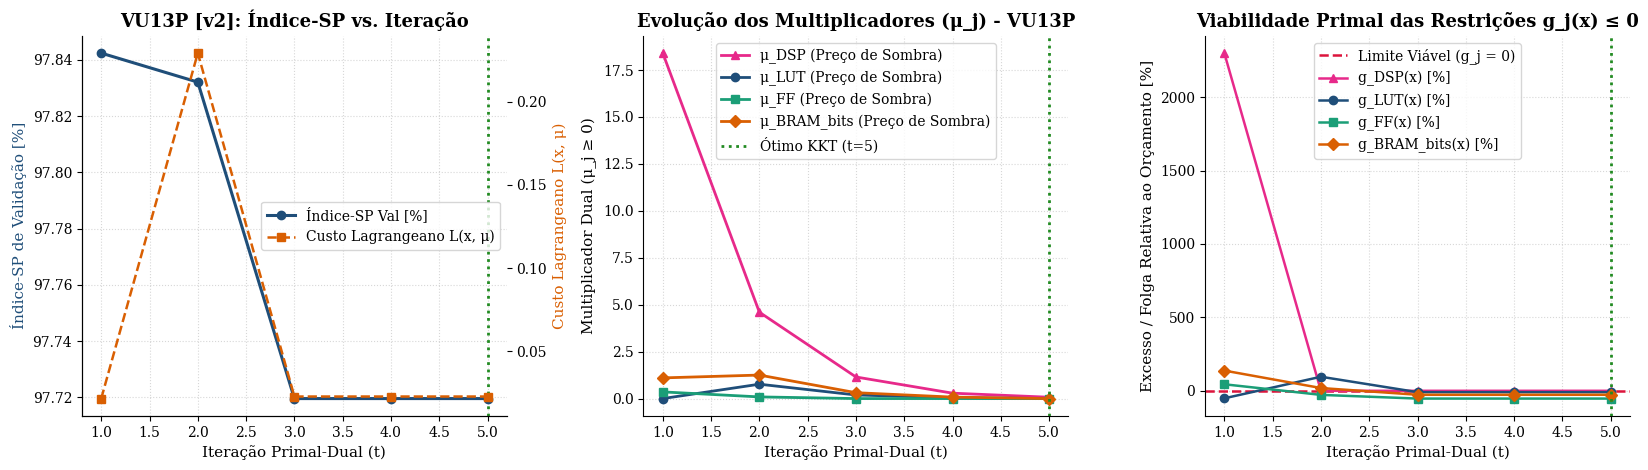

'/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/plots/kkt_primal_dual_evolution.png'

In [3]:
# Split de calibração para o ciclo Primal-Dual
X_tr_ref, X_val_ref, y_tr_ref, y_val_ref = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED
)

# Modelo de referência FP32 para Warm-Start e sensibilidade de 2ª ordem (Hutchinson)
model_fp32 = build_compact_cnn1d_fp32(
    input_dim=input_dim,
    num_filters=num_filters,
    kernel_size=kernel_size,
    dense_units=dense_units,
    learning_rate=1.5e-3,
)
sp_cb_fp32 = SPCallback(val_data=(X_val_ref, y_val_ref), patience=8, verbose=True)
lr_sched_fp32 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=0
)

history_fp32 = model_fp32.fit(
    X_tr_ref, y_tr_ref,
    validation_data=(X_val_ref, y_val_ref),
    epochs=EPOCHS_CV,
    batch_size=512,
    callbacks=[sp_cb_fp32, lr_sched_fp32],
    verbose=1,
)
sp_cb_fp32.restore_best_weights()
hw_fp32 = compute_model_hardware_costs(model_fp32, input_dim=input_dim)

y_pred_fp32_holdout = model_fp32.predict(X_holdout, batch_size=2048, verbose=0).ravel()
sp_fp32_ho, pd_fp32_ho, fa_fp32_ho, thresh_fp32_ho, _ = compute_sp_with_threshold(y_holdout, y_pred_fp32_holdout)
print(f"\n[Referência FP32 Holdout] SP = {sp_fp32_ho*100:.2f}% | PD = {pd_fp32_ho*100:.2f}% | FA = {fa_fp32_ho*100:.2f}%")

# Sensibilidade Hessiana de Hutchinson Tr(H_l) -> Coeficientes c_l
sample_idx = np.random.choice(len(X_val_ref), size=512, replace=False)
x_sample_tf = tf.convert_to_tensor(X_val_ref[sample_idx])
y_sample_tf = tf.convert_to_tensor(y_val_ref[sample_idx], dtype=tf.float32)[:, None]
bce_loss = keras.losses.BinaryCrossentropy()

traces = compute_hutchinson_hessian_trace(model_fp32, bce_loss, x_sample_tf, y_sample_tf, num_hvp=10, seed=SEED)
c_coeffs = compute_layer_c_coefficients(model_fp32, traces)

layer_names = [item["layer_name"] for item in hw_fp32["breakdown"]]
macs_list = [float(item["macs"]) for item in hw_fp32["breakdown"]]
params_list = [float(item["params"]) for item in hw_fp32["breakdown"]]
c_list = [c_coeffs[name] for name in layer_names]
bops_uniform_8bit = sum(m * 64.0 for m in macs_list)

# Inicialização do Núcleo de Otimização Lagrange / KKT na VU13P
kkt_optimizer = LagrangeKKTQuantizerOptimizer(
    hardware_limits=VU13P_INSTANCE_BUDGET,
    lr_x=0.05,
    lr_mu=0.80,
    normalize_constraints=True,
    slack_decay=0.25,
)

# Ponto inicial primal (t=1): Alta precisão (16 bits em pesos e ativações)
w_cfg = {"conv1d_1": 16, "dense_1": 16, "output_dense": 16}
a_cfg = {"conv1d_1": 16, "dense_1": 16}

sp_history_kkt = []
cached_eval = {}
last_kkt_sol = {}
MAX_PRIMAL_DUAL_ITERS = 8

print("\n=== Iniciando Ciclo Fechado de 3 Etapas: QKeras -> SP/VU13P -> Lagrange/KKT ===")
for t_step in range(1, MAX_PRIMAL_DUAL_ITERS + 1):
    cfg_key = (tuple(sorted(w_cfg.items())), tuple(sorted(a_cfg.items())))

    # --------------------------------------------------------------------------
    # ETAPA 1: REDE NEURAL QUANTIZADA (QKeras) - Configura (w_l, a_l, n_l) + Warm-Start
    # --------------------------------------------------------------------------
    if cfg_key not in cached_eval:
        q_cand = build_compact_qcnn1d(
            input_dim=input_dim,
            num_filters=num_filters,
            kernel_size=kernel_size,
            dense_units=dense_units,
            weights_bits=w_cfg,
            act_bits=a_cfg,
            learning_rate=8e-4,
        )
        transfer_weights_to_qmodel(model_fp32, q_cand)
        cb_cand = SPCallback(val_data=(X_val_ref, y_val_ref), patience=5, verbose=False)
        q_cand.fit(
            X_tr_ref, y_tr_ref,
            validation_data=(X_val_ref, y_val_ref),
            epochs=8,
            batch_size=512,
            callbacks=[cb_cand],
            verbose=0,
        )
        cb_cand.restore_best_weights()

        # ----------------------------------------------------------------------
        # ETAPA 2: AVALIAÇÃO DE DESEMPENHO (1 - SP) E CUSTO NA VU13P
        # ----------------------------------------------------------------------
        hw_cand = compute_model_hardware_costs(q_cand, weights_bits=w_cfg, act_bits=a_cfg, input_dim=input_dim)
        cached_eval[cfg_key] = (float(cb_cand.best_sp), hw_cand["vu13p_resources"])

    sp_t, res_t = cached_eval[cfg_key]
    sp_loss_t = 1.0 - sp_t
    sp_history_kkt.append(sp_t)

    # --------------------------------------------------------------------------
    # ETAPA 3: NÚCLEO DE OTIMIZAÇÃO LAGRANGE / KKT (Limites VU13P & Preços de Sombra μ_j)
    # --------------------------------------------------------------------------
    lag_cost_t, g_val_t = kkt_optimizer.lagrangian_penalty(sp_loss=sp_loss_t, resource_usage=res_t)
    kkt_optimizer.update_multipliers(g_val_t)

    converged_t, kkt_diag_t = check_kkt_stopping_criteria(
        sp_history=sp_history_kkt,
        g_val=g_val_t,
        mu=kkt_optimizer.mu,
        tol_sp=1e-3,
        tol_kkt=2e-2,
        window=2,
    )
    kkt_optimizer.record_step(
        iteration=t_step,
        sp_val=sp_t,
        w_bits=w_cfg,
        a_bits=a_cfg,
        resource_usage=res_t,
        g_val=g_val_t,
        lagrangian_cost=lag_cost_t,
        kkt_diag=kkt_diag_t,
    )

    print(
        f"  [Iter {t_step}] w={list(w_cfg.values())}b, a={list(a_cfg.values())}b | "
        f"SP={sp_t*100:.2f}% (1-SP={sp_loss_t:.4f}) | L(x,μ)={lag_cost_t:.4f} | "
        f"DSP={res_t['DSP']:.0f}, LUT={res_t['LUT']:.0f}, BRAM={res_t['BRAM_bits']:.0f}b | "
        f"μ=[DSP:{kkt_optimizer.mu['DSP']:.2f}, LUT:{kkt_optimizer.mu['LUT']:.2f}, BRAM:{kkt_optimizer.mu['BRAM_bits']:.2f}] | "
        f"KKT_OK={converged_t}"
    )

    if converged_t:
        print(f"  --> Convergência KKT Atingida na Iteração #{t_step} (Estacionaridade SP + Viabilidade Primal + Folga Complementar μ_j*g_j = 0)!")
        break

    # Atualização Primal Dinâmica guiada pelos Preços de Sombra μ_j
    w_cfg, a_cfg, last_kkt_sol = kkt_optimizer.compute_primal_bit_update(
        layer_names=layer_names,
        c_coeffs=c_list,
        macs_list=macs_list,
        params_list=params_list,
        current_w=w_cfg,
        current_a=a_cfg,
        b_min=2,
        b_max=8,
    )

kkt_weights_bits = dict(w_cfg)
kkt_act_bits = dict(a_cfg)

kkt_result = {
    **last_kkt_sol,
    "integer_bits": kkt_weights_bits,
    "activation_bits": kkt_act_bits,
    "vu13p_instance_budget": VU13P_INSTANCE_BUDGET,
    "primal_dual_history": kkt_optimizer.history,
    "final_multipliers_mu": kkt_optimizer.mu,
    "kkt_stopping_diagnostics": kkt_optimizer.history[-1]["kkt_diagnostics"],
}

# Visualização 2: Trajetória Primal-Dual KKT e Preços de Sombra (μ_j)
plot_primal_dual_kkt_evolution(
    kkt_history=kkt_optimizer.history,
    save_path=exporter.get_plot_path("kkt_primal_dual_evolution.png"),
    title_prefix=f"VU13P [v{VERSION}]",
    show=True,
)


## 3. Treinamento Final em Validação Cruzada ($K=5$ Folds) com *Warm-Start* e Avaliação Holdout

Com a configuração ótima $(w_l^*, a_l^*)$ determinada pelo núcleo Lagrange/KKT, realizamos a validação cruzada estratificada em 5 folds utilizando *Warm-Start* e `ReduceLROnPlateau` para máxima estabilidade estatística, exportando todos os modelos e metadados no padrão **Jubiaba**.


In [4]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

training_results_metadata = []
cv_records = []
folds_y_true = []
folds_y_pred = []

best_overall_sp = -1.0
best_fold_idx = 1
best_qmodel = None
best_history_dict = None

print(f"Iniciando {N_SPLITS}-Fold Cross-Validation para QCNN1D_KKT (w={kkt_weights_bits}, a={kkt_act_bits})...")

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    X_tr_f, y_tr_f = X_dev[tr_idx], y_dev[tr_idx]
    X_val_f, y_val_f = X_dev[val_idx], y_dev[val_idx]

    qmodel_f = build_compact_qcnn1d(
        input_dim=input_dim,
        num_filters=num_filters,
        kernel_size=kernel_size,
        dense_units=dense_units,
        weights_bits=kkt_weights_bits,
        act_bits=kkt_act_bits,
        learning_rate=1e-3,
    )
    transfer_weights_to_qmodel(model_fp32, qmodel_f)

    sp_cb_f = SPCallback(val_data=(X_val_f, y_val_f), patience=8, verbose=False)
    lr_sched_f = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=0
    )

    hist_f = qmodel_f.fit(
        X_tr_f, y_tr_f,
        validation_data=(X_val_f, y_val_f),
        epochs=EPOCHS_CV,
        batch_size=512,
        callbacks=[sp_cb_f, lr_sched_f],
        verbose=0,
    )
    sp_cb_f.restore_best_weights()

    fold_model_path = exporter.save_fold_model(qmodel_f, fold=fold_idx, repeat=1)

    y_val_pred = qmodel_f.predict(X_val_f, batch_size=2048, verbose=0).ravel()
    sp_f, pd_f, fa_f, thresh_f, _ = compute_sp_with_threshold(y_val_f, y_val_pred)
    fa_curve, pd_curve, _ = roc_curve(y_val_f, y_val_pred)
    auc_f = float(auc(fa_curve, pd_curve))

    folds_y_true.append(y_val_f)
    folds_y_pred.append(y_val_pred)

    cv_records.append({
        "fold": fold_idx,
        "repeat": 1,
        "sp_max": sp_f,
        "pd_knee": pd_f,
        "fa_knee": fa_f,
        "threshold_knee": thresh_f,
        "auc": auc_f,
        "best_epoch": sp_cb_f.best_epoch + 1,
        "model_path": os.path.basename(fold_model_path),
    })

    training_results_metadata.append({
        "fold": fold_idx,
        "repeat": 1,
        "max_sp": sp_f,
        "pd_knee": pd_f,
        "fa_knee": fa_f,
        "threshold_knee": thresh_f,
        "auc": auc_f,
        "best_epoch": sp_cb_f.best_epoch + 1,
        "keras_history": hist_f.history,
    })

    print(
        f"  [Fold {fold_idx}/{N_SPLITS}] SP = {sp_f*100:.2f}% | PD = {pd_f*100:.2f}% "
        f"| FA = {fa_f*100:.2f}% | AUC = {auc_f:.4f} | Salvo: {os.path.basename(fold_model_path)}"
    )

    if sp_f > best_overall_sp:
        best_overall_sp = sp_f
        best_fold_idx = fold_idx
        best_qmodel = qmodel_f
        best_history_dict = hist_f.history

cv_df = pd.DataFrame(cv_records)
print(f"\nMelhor Fold: #{best_fold_idx} com SP = {best_overall_sp*100:.2f}%")
print(
    f"Média CV ({N_SPLITS} Folds): SP = {cv_df['sp_max'].mean()*100:.2f}% ± {cv_df['sp_max'].std()*100:.2f}% | "
    f"PD = {cv_df['pd_knee'].mean()*100:.2f}% | FA = {cv_df['fa_knee'].mean()*100:.2f}%"
)

# Avaliação Final no Holdout Isolado
y_pred_holdout = best_qmodel.predict(X_holdout, batch_size=2048, verbose=0).ravel()
sp_ho, pd_ho, fa_ho, thresh_ho, _ = compute_sp_with_threshold(y_holdout, y_pred_holdout)
hw_qkeras_kkt = compute_model_hardware_costs(
    best_qmodel, weights_bits=kkt_weights_bits, act_bits=kkt_act_bits, input_dim=input_dim
)

print(f"\n[Holdout Test Set - Melhor Modelo QKeras KKT (Fold #{best_fold_idx})]")
print(f"  • SP = {sp_ho*100:.2f}% | PD = {pd_ho*100:.2f}% | FA = {fa_ho*100:.2f}% | Limiar = {thresh_ho:.4f}")
print(f"  • Hardware: {hw_qkeras_kkt['total_bops']:,} BOPs | {hw_qkeras_kkt['total_macs']:,} MACs | {hw_qkeras_kkt['total_params']} Parâmetros")
print(f"  • Recursos VU13P: {hw_qkeras_kkt['vu13p_resources']}")

# Exportação Hierárquica Jubiaba
exporter.save_best_model(best_qmodel, input_dim=input_dim)
exporter.save_history(best_history_dict)
exporter.save_evaluation_splits(X_holdout, y_holdout, y_pred_holdout, threshold=thresh_ho)
exporter.save_metadata(
    training_results=training_results_metadata,
    cv_df=cv_df,
    kkt_result=kkt_result,
    extra_config={
        "rings_structure": estrutura_v,
        "vu13p_chip_limits": VU13P_LIMITS,
        "vu13p_instance_budget": VU13P_INSTANCE_BUDGET,
        "hardware_fp32": hw_fp32,
        "hardware_qkeras_kkt": hw_qkeras_kkt,
        "holdout_metrics": {
            "sp": sp_ho,
            "pd": pd_ho,
            "fa": fa_ho,
            "threshold": thresh_ho,
            "fp32_sp": sp_fp32_ho,
            "fp32_pd": pd_fp32_ho,
            "fp32_fa": fa_fp32_ho,
        },
    },
    seed=SEED,
)


Iniciando 5-Fold Cross-Validation para QCNN1D_KKT (w={'conv1d_1': 2, 'dense_1': 5, 'output_dense': 8}, a={'conv1d_1': 8, 'dense_1': 8})...


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 1/5] SP = 97.69% | PD = 98.65% | FA = 3.27% | AUC = 0.9935 | Salvo: model_v2_f1_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 2/5] SP = 97.54% | PD = 98.56% | FA = 3.47% | AUC = 0.9940 | Salvo: model_v2_f2_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


... (2 outputs left out)

  [Fold 4/5] SP = 97.93% | PD = 98.90% | FA = 3.03% | AUC = 0.9949 | Salvo: model_v2_f4_r1.keras


/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(
/home/iaraujo/Documentos/Github/cnn-optimization/.venv/lib64/python3.11/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


  [Fold 5/5] SP = 97.78% | PD = 99.08% | FA = 3.52% | AUC = 0.9941 | Salvo: model_v2_f5_r1.keras

Melhor Fold: #4 com SP = 97.93%
Média CV (5 Folds): SP = 97.68% ± 0.18% | PD = 98.82% | FA = 3.45%

[Holdout Test Set - Melhor Modelo QKeras KKT (Fold #4)]
  • SP = 97.80% | PD = 98.37% | FA = 2.77% | Limiar = 0.7346
  • Hardware: 40,832 BOPs | 1,376 MACs | 817 Parâmetros
  • Recursos VU13P: {'DSP': 0.0, 'LUT': 2268.4444444444443, 'FF': 4704.0, 'BRAM_bits': 4016.0}


{'pkl_path': '/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/training_metadata_v2.pkl',
 'json_path': '/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/training_metadata_v2.json',
 'cv_csv_path': '/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/cross_validation_results.csv',
 'repro_path': '/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/reproducibility_metadata.json',
 'kkt_path': '/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/kkt_allocation_results.json'}

## 4. Diagnóstico Visual de Recursos na VU13P e Desempenho Físico (`codeTCC` + `Jubiaba`)

Geramos os gráficos de utilização de recursos na FPGA Virtex UltraScale+ VU13P, curvas de aprendizado, curvas ROC (melhor modelo, duelo FP32 vs. KKT e envoltória dos 5 folds), distribuição de scores, matriz de confusão no joelho $SP$ e boxplots de estabilidade.


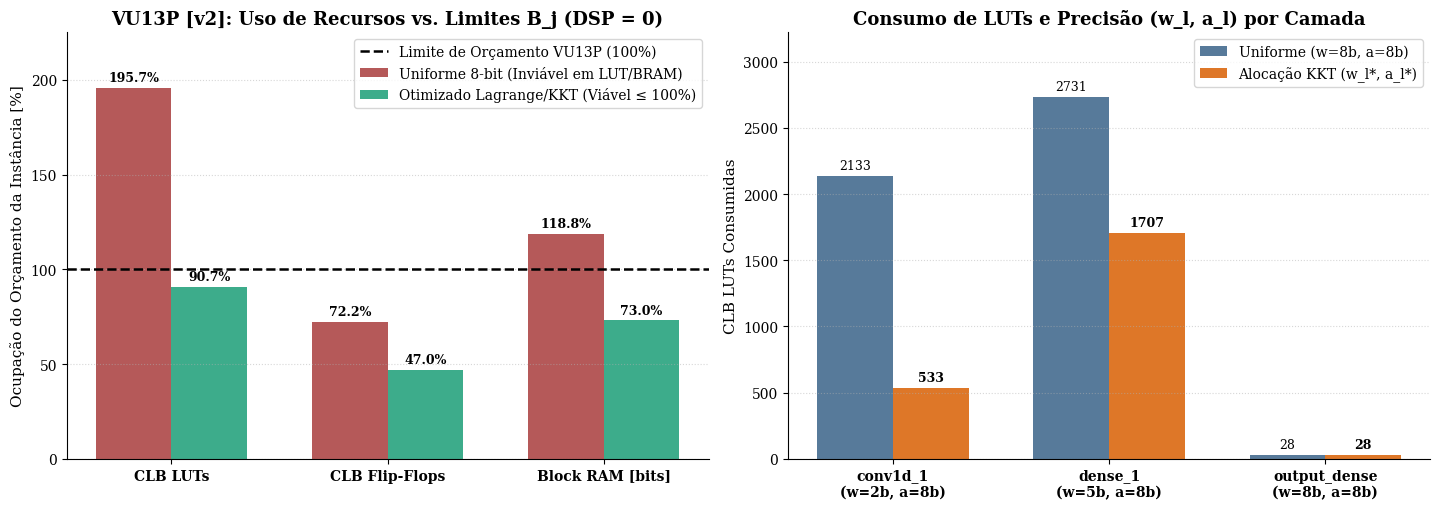

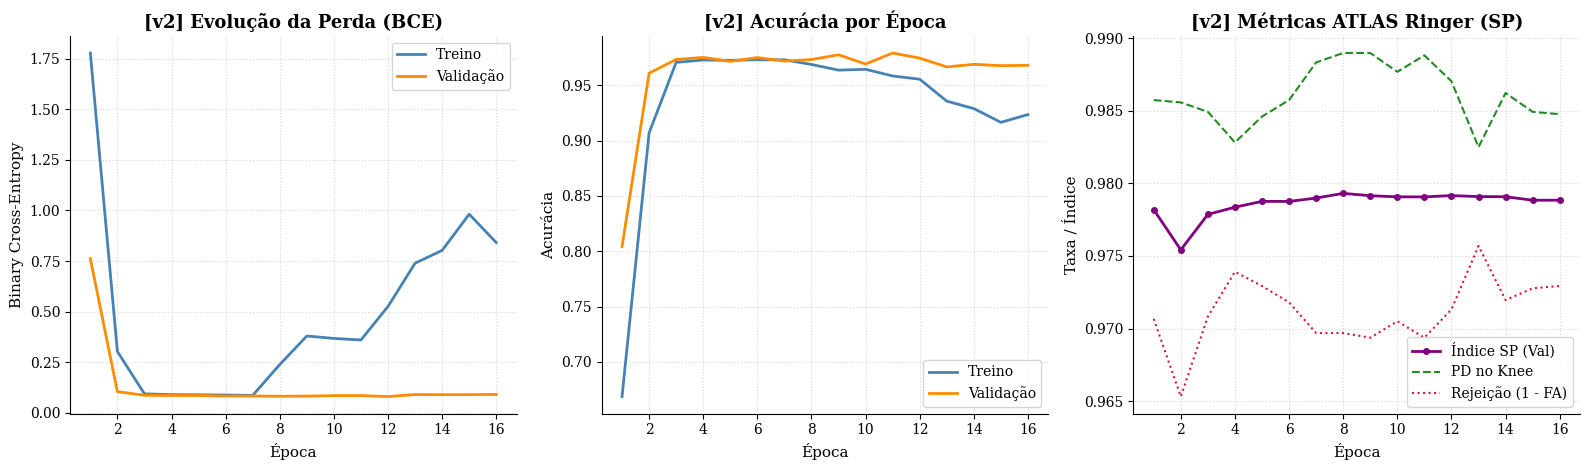

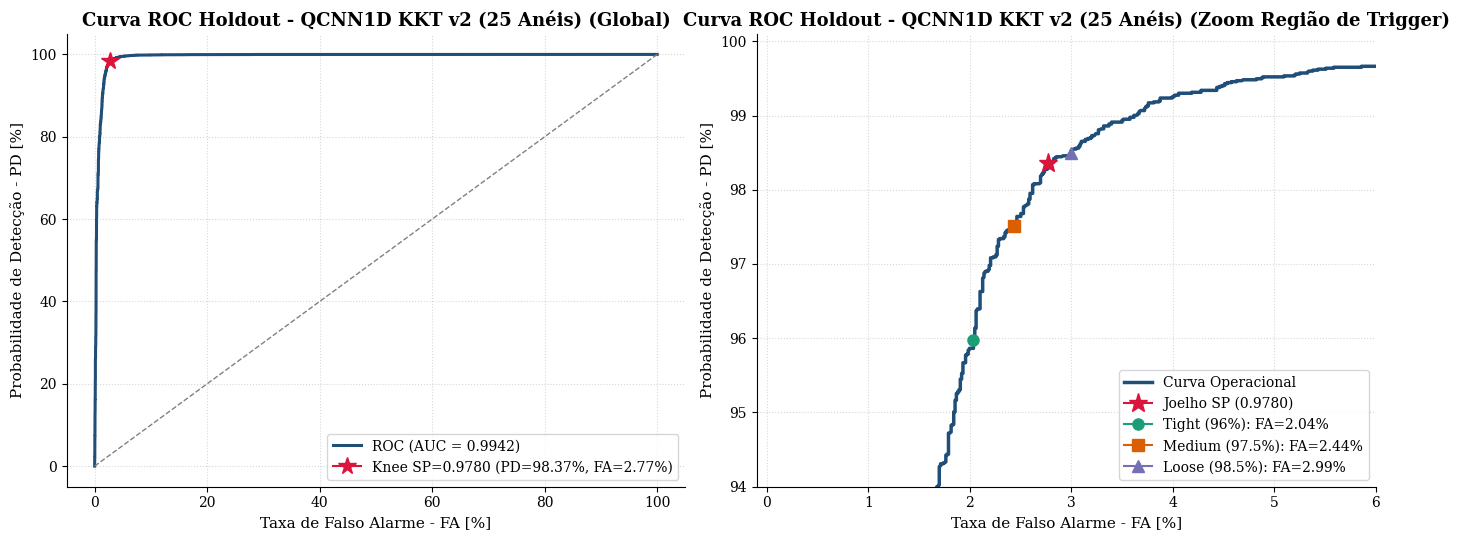

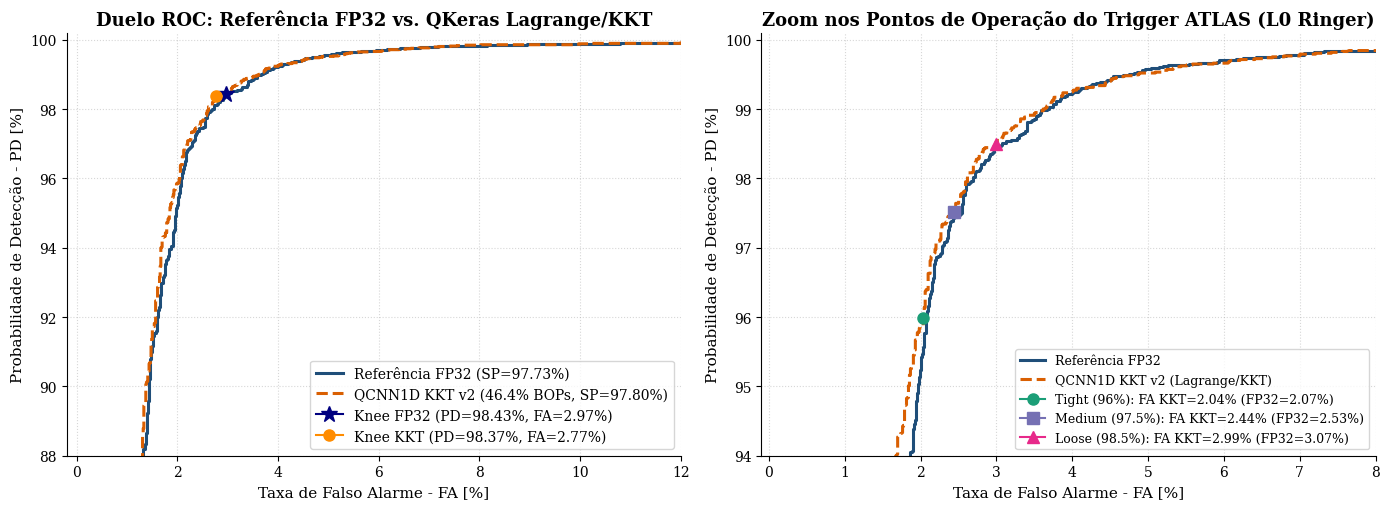

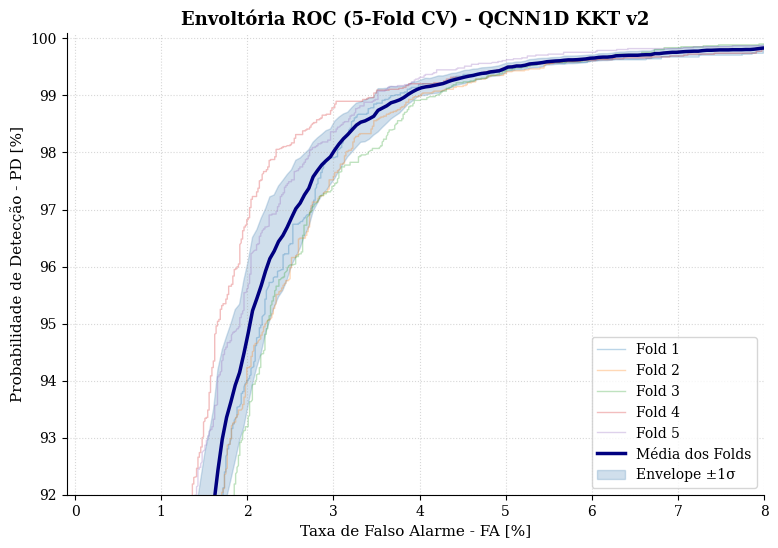

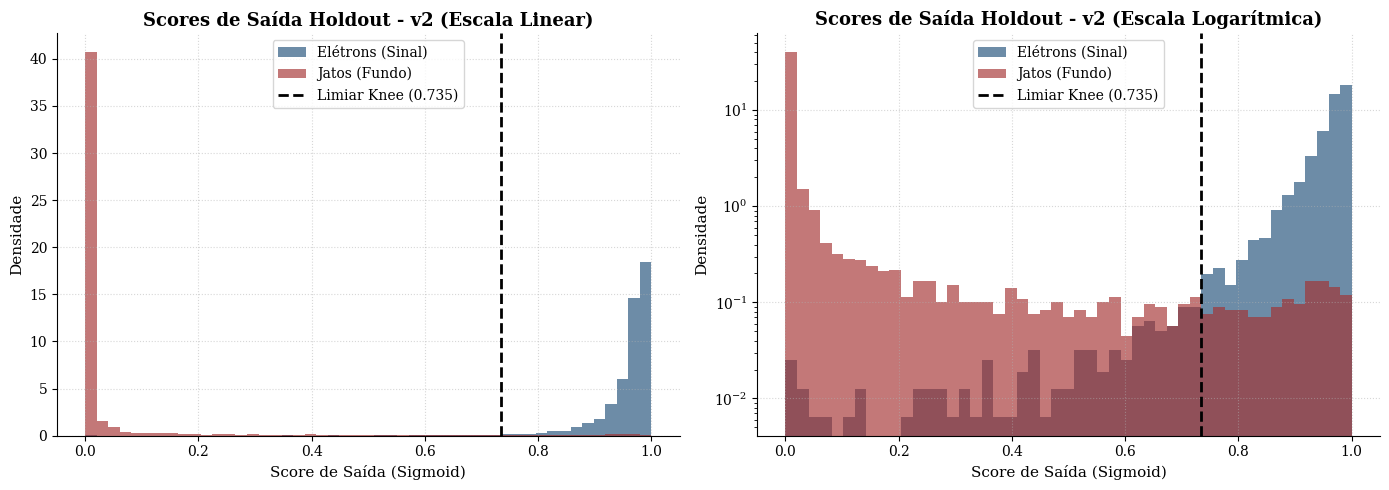

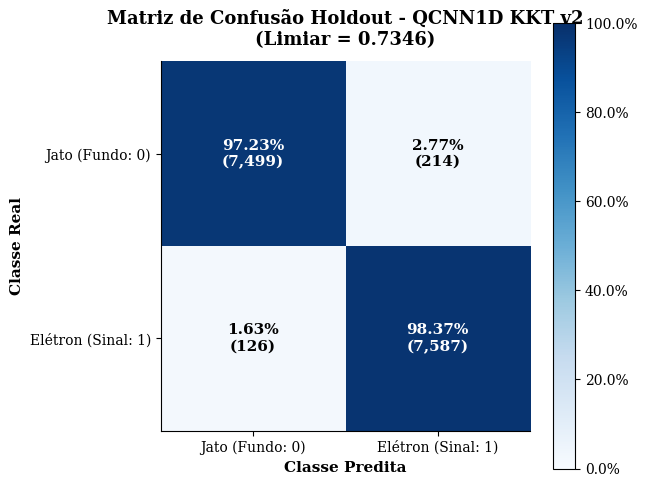

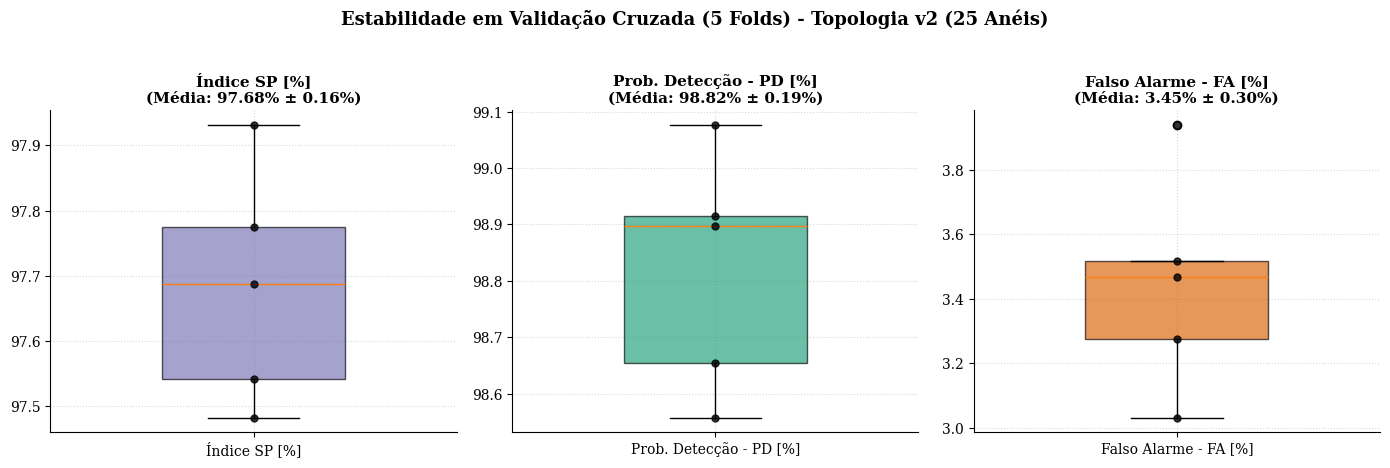

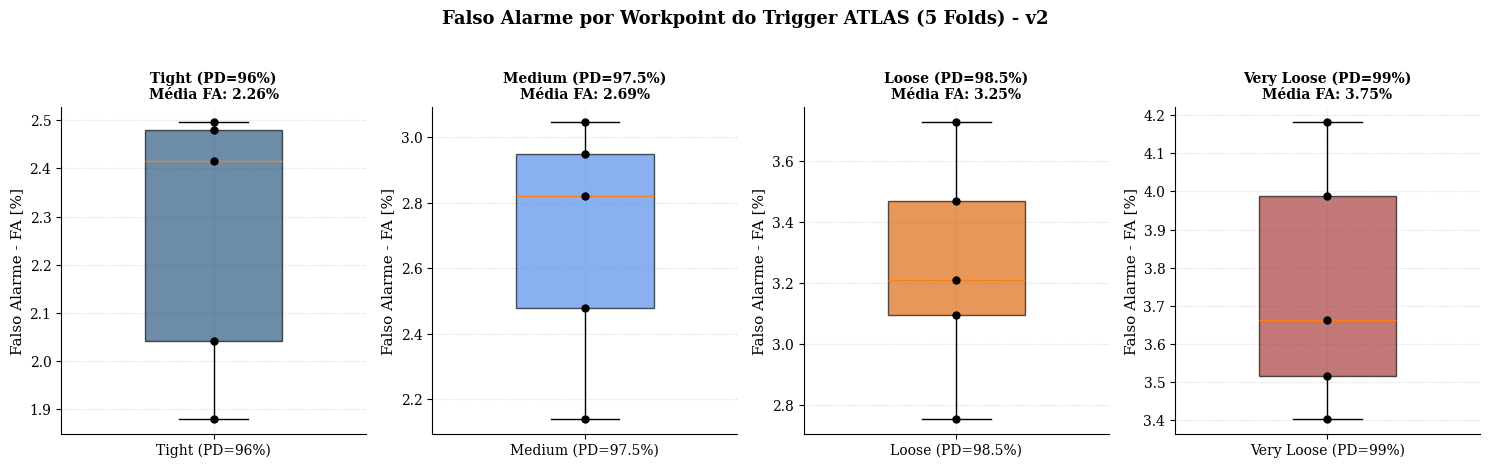

'/home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/plots/fa_per_fold_workpoints.png'

In [5]:
# 3. Ocupação de Recursos na FPGA Virtex UltraScale+ VU13P e Alocação de Bits por Camada
plot_vu13p_resource_utilization(
    hw_8bit=hw_fp32,
    hw_kkt=hw_qkeras_kkt,
    vu13p_budget=VU13P_INSTANCE_BUDGET,
    save_path=exporter.get_plot_path("vu13p_resource_utilization.png"),
    title_prefix=f"VU13P [v{VERSION}]",
    show=True,
)

# 4. Curvas de Aprendizado da Melhor Execução
plot_learning_curves(
    history_dict=best_history_dict,
    save_path=exporter.get_plot_path("learning_curves.png"),
    title_prefix=f"[v{VERSION}]",
    show=True,
)

# 5. Curva ROC do Melhor Modelo (Global + Zoom Operacional)
plot_best_model_roc(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    sp_val=sp_ho,
    pd_knee=pd_ho,
    fa_knee=fa_ho,
    save_path=exporter.get_plot_path("roc_best_model.png"),
    title=f"Curva ROC Holdout - QCNN1D KKT v{VERSION} ({input_dim} Anéis)",
    show=True,
)

# 6. Duelo ROC: Referência FP32 vs. QKeras Lagrange/KKT (Global + Zoom nos Working Points ATLAS)
plot_roc_duel_fp32_vs_kkt(
    y_val=y_holdout,
    y_pred_fp32=y_pred_fp32_holdout,
    sp_fp32=sp_fp32_ho,
    pd_fp32=pd_fp32_ho,
    fa_fp32=fa_fp32_ho,
    y_pred_q=y_pred_holdout,
    sp_q=sp_ho,
    pd_q=pd_ho,
    fa_q=fa_ho,
    bops_ratio=hw_qkeras_kkt["total_bops"] / bops_uniform_8bit,
    save_path=exporter.get_plot_path("roc_duel_fp32_vs_kkt.png"),
    title_prefix=f"QCNN1D KKT v{VERSION}",
    show=True,
)

# 7. Envoltória ROC da Validação Cruzada
plot_cv_roc_envelope(
    folds_y_true=folds_y_true,
    folds_y_pred=folds_y_pred,
    save_path=exporter.get_plot_path("roc_cv_envelope.png"),
    title=f"Envoltória ROC ({N_SPLITS}-Fold CV) - QCNN1D KKT v{VERSION}",
    show=True,
)

# 8. Histograma de Scores da Saída (Linear e Log)
plot_output_score_histogram(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    threshold_knee=thresh_ho,
    save_path=exporter.get_plot_path("output_scores_hist.png"),
    title=f"Scores de Saída Holdout - v{VERSION}",
    show=True,
)

# 9. Matriz de Confusão no Ponto de Joelho (SP Knee)
plot_confusion_matrix_knee(
    y_true=y_holdout,
    y_pred=y_pred_holdout,
    threshold_knee=thresh_ho,
    save_path=exporter.get_plot_path("confusion_matrix_knee.png"),
    title=f"Matriz de Confusão Holdout - QCNN1D KKT v{VERSION}",
    show=True,
)

# 10. Boxplots de Estabilidade em Validação Cruzada e Falso Alarme por Workpoint
plot_cv_statistics_boxplots(
    cv_df=cv_df,
    save_path=exporter.get_plot_path("cv_boxplots.png"),
    title=f"Estabilidade em Validação Cruzada ({N_SPLITS} Folds) - Topologia v{VERSION} ({input_dim} Anéis)",
    show=True,
)

plot_fa_per_fold_workpoints(
    folds_y_true=folds_y_true,
    folds_y_pred=folds_y_pred,
    save_path=exporter.get_plot_path("fa_per_fold_workpoints.png"),
    title=f"Falso Alarme por Workpoint do Trigger ATLAS ({N_SPLITS} Folds) - v{VERSION}",
    show=True,
)


## 5. Tabela de Quantização Final por Camada, Recursos na VU13P e Árvore Jubiaba

Consolidamos a tabela detalhada de precisão $(w_l^*, a_l^*, n_l)$ por camada `QConv1D`/`QDense`, o comparativo global de recursos na FPGA **Virtex UltraScale+ VU13P** e a listagem dos artefatos exportados.


In [6]:
layer_quant_rows = []
for item in hw_qkeras_kkt["breakdown"]:
    layer_quant_rows.append({
        "Camada QKeras": item["layer_name"],
        "Tipo": item["layer_type"],
        "Filtros/Unidades (n_l)": item["units"],
        "Bits Pesos (w_l)": item["b_w"],
        "Bits Ativação (a_l)": item["b_a"],
        "Parâmetros": item["params"],
        "MACs": item["macs"],
        "BOPs": item["bops"],
        "VU13P DSPs": int(item["DSP"]),
        "VU13P LUTs": f"{item['LUT']:.1f}",
        "VU13P FFs": f"{item['FF']:.1f}",
        "VU13P BRAM [bits]": int(item["BRAM_bits"]),
    })

df_layer_quant = pd.DataFrame(layer_quant_rows)
print("=== Tabela de Quantização Final por Camada e Consumo na FPGA VU13P ===")
display(df_layer_quant)

res_fp32_8b = hw_fp32["vu13p_resources"]
res_kkt = hw_qkeras_kkt["vu13p_resources"]

summary_df = pd.DataFrame([
    {
        "Topologia": f"v{VERSION} ({input_dim} Anéis)",
        "Modelo": "Referência (Equiv. 8-bit Uniforme)",
        "Precisão (w_l / a_l)": "w: [8, 8, 8]b | a: [8, 8]b",
        "SP Holdout [%]": f"{sp_fp32_ho*100:.2f}%",
        "PD Holdout [%]": f"{pd_fp32_ho*100:.2f}%",
        "FA Holdout [%]": f"{fa_fp32_ho*100:.2f}%",
        "BOPs": f"{hw_fp32['total_bops']:,}",
        "VU13P DSPs": int(res_fp32_8b["DSP"]),
        "VU13P LUTs": f"{res_fp32_8b['LUT']:,.0f}",
        "VU13P FFs": f"{res_fp32_8b['FF']:,.0f}",
        "VU13P BRAM [bits]": f"{res_fp32_8b['BRAM_bits']:,.0f}",
    },
    {
        "Topologia": f"v{VERSION} ({input_dim} Anéis)",
        "Modelo": "QCNN1D KKT Primal-Dual (Melhor Fold)",
        "Precisão (w_l / a_l)": f"w: [{kkt_weights_bits['conv1d_1']}, {kkt_weights_bits['dense_1']}, {kkt_weights_bits['output_dense']}]b | a: [{kkt_act_bits['conv1d_1']}, {kkt_act_bits['dense_1']}]b",
        "SP Holdout [%]": f"{sp_ho*100:.2f}%",
        "PD Holdout [%]": f"{pd_ho*100:.2f}%",
        "FA Holdout [%]": f"{fa_ho*100:.2f}%",
        "BOPs": f"{hw_qkeras_kkt['total_bops']:,}",
        "VU13P DSPs": int(res_kkt["DSP"]),
        "VU13P LUTs": f"{res_kkt['LUT']:,.0f}",
        "VU13P FFs": f"{res_kkt['FF']:,.0f}",
        "VU13P BRAM [bits]": f"{res_kkt['BRAM_bits']:,.0f}",
    },
])
print("\n=== Comparativo Global de Desempenho Físico e Recursos na VU13P ===")
display(summary_df)

print(f"\n=== Árvore de Artefatos Gerada em: {exporter.base_dir} ===")
for root, dirs, files in os.walk(exporter.base_dir):
    level = root.replace(exporter.base_dir, "").count(os.sep)
    indent = "  " * level
    folder_name = os.path.basename(root) if level > 0 else f"v{VERSION}/"
    print(f"{indent}├── {folder_name}/")
    subindent = "  " * (level + 1)
    for f_name in sorted(files):
        f_path = os.path.join(root, f_name)
        size_kb = os.path.getsize(f_path) / 1024.0
        print(f"{subindent}└── {f_name} ({size_kb:.1f} KB)")


=== Tabela de Quantização Final por Camada e Consumo na FPGA VU13P ===


,Camada QKeras,Tipo,Filtros/Unidades (n_l),Bits Pesos (w_l),Bits Ativação (a_l),Parâmetros,MACs,BOPs,VU13P DSPs,VU13P LUTs,VU13P FFs,VU13P BRAM [bits]
0,conv1d_1,QConv1D,8,2,8,32,600,9600,0,533.3,364.0,64
1,dense_1,QDense,8,5,8,776,768,30720,0,1706.7,4264.0,3880
2,output_dense,QDense,1,8,8,9,8,512,0,28.4,76.0,72



=== Comparativo Global de Desempenho Físico e Recursos na VU13P ===


,Topologia,Modelo,Precisão (w_l / a_l),SP Holdout [%],PD Holdout [%],FA Holdout [%],BOPs,VU13P DSPs,VU13P LUTs,VU13P FFs,VU13P BRAM [bits]
0,v2 (25 Anéis),Referência (Equiv. 8-bit Uniforme),"w: [8, 8, 8]b | a: [8, 8]b",97.73%,98.43%,2.97%,"88,064",0,"4,892","7,224","6,536"
1,v2 (25 Anéis),QCNN1D KKT Primal-Dual (Melhor Fold),"w: [2, 5, 8]b | a: [8, 8]b",97.80%,98.37%,2.77%,"40,832",0,"2,268","4,704","4,016"



=== Árvore de Artefatos Gerada em: /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2 ===
├── v2//
  ├── saved_models/
    └── best_model.keras (49.8 KB)
    └── best_model.onnx (0.7 KB)
    └── model_v2_f1_r1.keras (49.8 KB)
    └── model_v2_f2_r1.keras (49.8 KB)
    └── model_v2_f3_r1.keras (49.8 KB)
    └── model_v2_f4_r1.keras (49.8 KB)
    └── model_v2_f5_r1.keras (49.8 KB)
  ├── plots/
    └── confusion_matrix_knee.png (159.2 KB)
    └── cv_boxplots.png (220.2 KB)
    └── fa_per_fold_workpoints.png (244.9 KB)
    └── kkt_primal_dual_evolution.png (565.1 KB)
    └── learning_curves.png (411.4 KB)
    └── output_scores_hist.png (194.8 KB)
    └── rings_profile_v2.png (233.2 KB)
    └── roc_best_model.png (343.4 KB)
    └── roc_cv_envelope.png (291.6 KB)
    └── roc_duel_fp32_vs_kkt.png (394.0 KB)
    └── vu13p_resource_utilization.png (307.5 KB)
  ├── history/
    └── history.json (3.2 KB)
    └── training_history.csv 